# 12 — Motion & Tracking

Each concept uses **Intuition → Straight definition → Example**. We use `opencv_sample_video.mp4`.

## 1. Motion Detection

**Intuition:** If consecutive frames are different, something probably moved.

**Definition:** Motion detection finds pixels that change between frames.

**Example:** Subtract two grayscale frames.

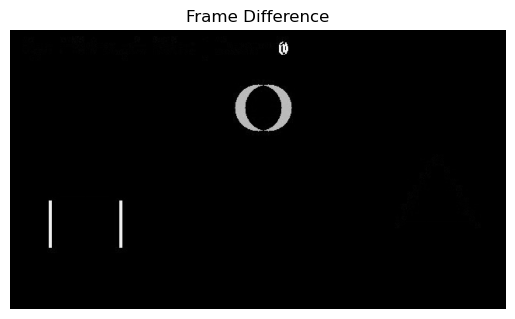

In [2]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

video_path = "opencv_sample_video.mp4"
cap = cv2.VideoCapture(video_path)
ret1, frame1 = cap.read()
ret2, frame2 = cap.read()
cap.release()

g1 = cv2.cvtColor(frame1, cv2.COLOR_BGR2GRAY)
g2 = cv2.cvtColor(frame2, cv2.COLOR_BGR2GRAY)
diff = cv2.absdiff(g1, g2)

plt.imshow(diff, cmap="gray")
plt.axis("off")
plt.title("Frame Difference")
plt.show()

## 2. Threshold the Difference

**Intuition:** Ignore tiny changes and keep strong changes.

**Definition:** Thresholding converts the difference image into a binary motion mask.

**Example:** Pixels above 25 become white.

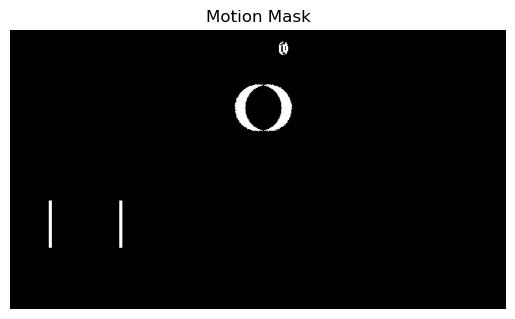

In [3]:
_, mask = cv2.threshold(diff, 25, 255, cv2.THRESH_BINARY)
plt.imshow(mask, cmap="gray")
plt.axis("off")
plt.title("Motion Mask")
plt.show()

## 3. Find Moving Objects

**Intuition:** White regions in the mask represent possible moving objects.

**Definition:** `findContours()` extracts their boundaries.

**Example:** Draw a bounding box around each sufficiently large contour.

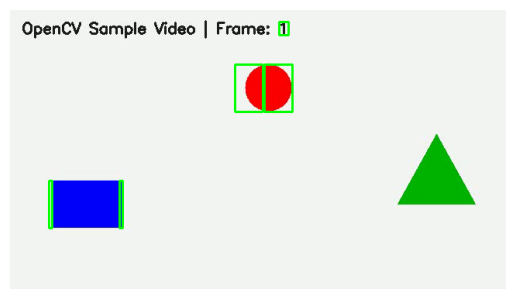

In [4]:
contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

result = frame2.copy()

for c in contours:
    if cv2.contourArea(c) < 20: 
        continue
    
    x,y,w,h = cv2.boundingRect(c)
    
    cv2.rectangle(result,(x,y),(x+w,y+h),(0,255,0),2)

plt.imshow(cv2.cvtColor(result, cv2.COLOR_BGR2RGB))

plt.axis("off")

plt.show()

## 4. Blur Before Detection

**Intuition:** Noise can look like movement; blur removes small variations.

**Definition:** Gaussian blur smooths neighboring pixels before frame differencing.

**Example:** `GaussianBlur(gray, (5,5), 0)`.

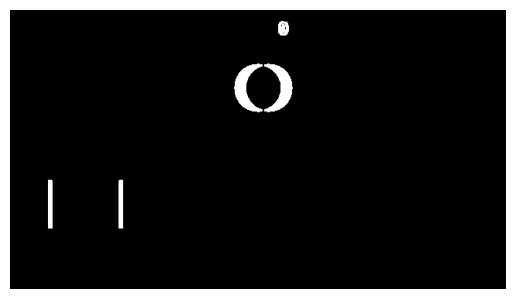

In [6]:
b1=cv2.GaussianBlur(g1,(5,5),0)
b2=cv2.GaussianBlur(g2,(5,5),0)
d=cv2.absdiff(b1,b2)
_,m=cv2.threshold(d,20,255,cv2.THRESH_BINARY)
plt.imshow(m,cmap="gray")
plt.axis("off")
plt.show()

## 5. Background Subtraction (MOG2)

**Intuition:** Learn what normally belongs to the background, then detect what does not.

**Definition:** MOG2 maintains a statistical background model and produces a foreground mask.

**Important parameters:** `history`, `varThreshold`, `detectShadows`.

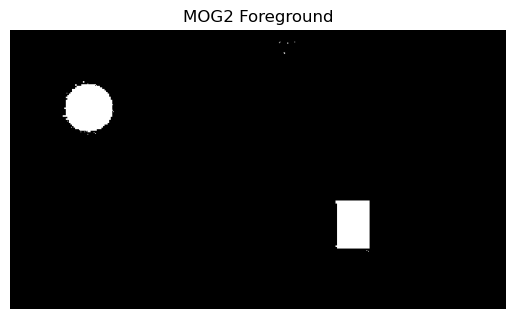

In [7]:
cap=cv2.VideoCapture(video_path)
bg=cv2.createBackgroundSubtractorMOG2(history=100,varThreshold=40,detectShadows=False)

for _ in range(80):
    ret,frame=cap.read()
    if not ret: break
    fg=bg.apply(frame)

cap.release()

plt.imshow(fg,cmap="gray")
plt.axis("off")
plt.title("MOG2 Foreground")
plt.show()

## 6. Tracking

**Intuition:** Motion detection says **something moved**; tracking tries to follow **the same object**.

**Definition:** Tracking estimates an object position across frames.

**Example:** Track the center of the largest moving contour.

In [8]:
cap = cv2.VideoCapture(video_path)
prev = None
centers = []
while True:
    ret,frame = cap.read()
    if not ret: break
    gray = cv2.GaussianBlur(cv2.cvtColor(frame,cv2.COLOR_BGR2GRAY),(5,5),0)
    if prev is None: 
        prev = gray
        continue
    d = cv2.absdiff(prev,gray)
    _,m = cv2.threshold(d,20,255,cv2.THRESH_BINARY)
    cs,_ = cv2.findContours(m,cv2.RETR_EXTERNAL,cv2.CHAIN_APPROX_SIMPLE)
    if cs:
        c = max(cs,key = cv2.contourArea)
        if cv2.contourArea(c)>30:
            x,y,w,h = cv2.boundingRect(c); centers.append((x+w//2,y+h//2))
    prev = gray
cap.release()
print("Tracked positions:",len(centers))
print(centers[:5])

Tracked positions: 239
[(346, 100), (360, 100), (373, 100), (348, 100), (400, 100)]


## 7. Centroid

**Intuition:** The center of an object is a simple point to follow.

**Definition:** For contour moments, `cx=M10/M00` and `cy=M01/M00`.

**Example:**

In [9]:
M=cv2.moments(contours[0])
if M["m00"] != 0:
    cx=int(M["m10"]/M["m00"]); cy=int(M["m01"]/M["m00"])
    print("Centroid:",(cx,cy))

Centroid: (142, 250)


## 8. Trajectory

**Intuition:** Store the center at every frame and connect the points to see the path.

**Definition:** A trajectory is the sequence of estimated positions over time.

**Example:**

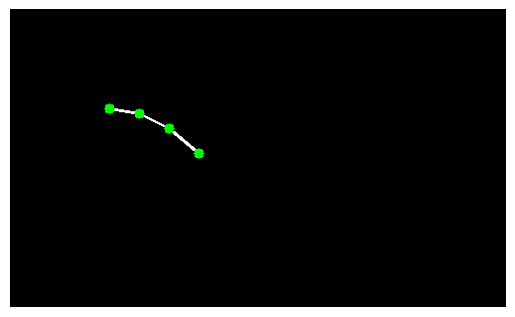

In [11]:
canvas=np.zeros((300,500,3),dtype=np.uint8)
points=[(100,100),(130,105),(160,120),(190,145)]
for a,b in zip(points,points[1:]): cv2.line(canvas,a,b,(255,255,255),2)
for p in points: cv2.circle(canvas,p,5,(0,255,0),-1)
plt.imshow(cv2.cvtColor(canvas,cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.show()

## 9. Optical Flow

**Intuition:** Instead of only asking whether something changed, optical flow asks **how image points moved**.

**Definition:** Optical flow estimates displacement vectors between frames.

**Example:** A point moving right may have `(u=5,v=0)`.

### Lucas–Kanade

**Intuition:** Track selected good points.

**Definition:** `calcOpticalFlowPyrLK()` estimates motion of selected feature points.

In [12]:
cap=cv2.VideoCapture(video_path)
ret,f1=cap.read(); ret,f2=cap.read(); cap.release()
g1=cv2.cvtColor(f1,cv2.COLOR_BGR2GRAY); g2=cv2.cvtColor(f2,cv2.COLOR_BGR2GRAY)
p0=cv2.goodFeaturesToTrack(g1,maxCorners=50,qualityLevel=.3,minDistance=7)
p1,status,error=cv2.calcOpticalFlowPyrLK(g1,g2,p0,None)
print("Initial:",len(p0) if p0 is not None else 0,"Tracked:",int(status.sum()) if status is not None else 0)

Initial: 50 Tracked: 50


### Dense Optical Flow

**Intuition:** Lucas–Kanade tracks selected points; dense flow estimates motion across almost the whole image.

**Definition:** Farneback produces a motion vector for image regions/pixels.

In [13]:
flow=cv2.calcOpticalFlowFarneback(g1,g2,None,.5,3,15,3,5,1.2,0)
mag,angle=cv2.cartToPolar(flow[...,0],flow[...,1])
print("Flow shape:",flow.shape,"Average magnitude:",mag.mean())

Flow shape: (360, 640, 2) Average magnitude: 0.48818007


## 10. Optical Flow Math

Brightness constancy assumes `I(x,y,t)=I(x+dx,y+dy,t+dt)`.

Using a first-order Taylor approximation gives:

`Ix*u + Iy*v + It = 0`

where `u=dx/dt` and `v=dy/dt`. This is the basic optical-flow constraint.

## 11. Complete Pipeline

**Intuition:** A practical fixed-camera motion detector combines simple operations.

**Definition:** `Video → Gray → Blur → Difference → Threshold → Morphology → Contours → Bounding boxes`.

**Example:**

In [14]:
cap=cv2.VideoCapture(video_path); prev=None; count=0
kernel=np.ones((3,3),np.uint8)
while True:
    ret,frame=cap.read()
    if not ret: break
    gray=cv2.GaussianBlur(cv2.cvtColor(frame,cv2.COLOR_BGR2GRAY),(5,5),0)
    if prev is None: prev=gray; continue
    d=cv2.absdiff(prev,gray); _,m=cv2.threshold(d,20,255,cv2.THRESH_BINARY)
    m=cv2.morphologyEx(m,cv2.MORPH_OPEN,kernel)
    cs,_=cv2.findContours(m,cv2.RETR_EXTERNAL,cv2.CHAIN_APPROX_SIMPLE)
    count += sum(cv2.contourArea(c)>30 for c in cs)
    prev=gray
cap.release(); print("Motion regions:",count)

Motion regions: 1252


# Summary

- Frame difference → detects changes.
- Background subtraction → detects foreground.
- Contours → turn motion masks into regions.
- Tracking → follows an object.
- Centroid → gives a simple object position.
- Optical flow → estimates motion vectors.
- Lucas–Kanade → sparse point tracking.
- Farneback → dense optical flow.